# Automated Flood Risk Assessment: Rönne å Basin, Sweden
**Author:** Avwerosuo Udjoh

This notebook automates the data acquisition, statistical analysis, and spatial mapping of flood risk for the Rönne å river in southern Sweden.

In [7]:
import requests
import io
import pandas as pd

# 1. The CORRECT Hydrological API URL for Discharge (Parameter 1)
url = "https://opendata-download-hydroobs.smhi.se/api/version/1.0/parameter/1/station/2357/period/corrected-archive/data.csv"

print("Fetching streamflow CSV from SMHI (Hydroobs API)...")
response = requests.get(url)

if response.status_code == 200:
    print("Data fetched successfully. Parsing...")
    # Decode using 'utf-8-sig' to handle potential Byte Order Marks
    text_data = response.content.decode('utf-8-sig')

    # 2. Find the exact line where the data table starts
    lines = text_data.splitlines()
    header_index = 0
    for i, line in enumerate(lines):
        if line.lower().startswith("datum") or line.lower().startswith("date"):
            header_index = i
            break

    print(f"Data header found at line {header_index}. Reading data...")

    # 3. Read the CSV into Pandas
    df_flow = pd.read_csv(
        io.StringIO(text_data),
        sep=';',
        skiprows=header_index,
        usecols=[0, 1, 2],
        names=['Date', 'Time', 'Flow_m3s']
    )

    # 4. Clean the data
    df_flow['Date'] = pd.to_datetime(df_flow['Date'] + ' ' + df_flow['Time'], errors='coerce')
    df_flow = df_flow.dropna(subset=['Date'])
    df_flow['Flow_m3s'] = pd.to_numeric(df_flow['Flow_m3s'], errors='coerce')
    df_flow = df_flow.dropna(subset=['Flow_m3s'])

    # 5. Extract the ANNUAL MAXIMUM flow for each year
    df_flow['Year'] = df_flow['Date'].dt.year
    annual_max = df_flow.groupby('Year')['Flow_m3s'].max().reset_index()

    print(f"\nFound {len(annual_max)} years of data!")
    print(annual_max.head())
else:
    print(f"Error: Status code {response.status_code}. Could not fetch data.")

Fetching streamflow CSV from SMHI (Hydroobs API)...
Data fetched successfully. Parsing...
Data header found at line 6. Reading data...


/tmp/ipykernel_485/1778882002.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_flow['Date'] = pd.to_datetime(df_flow['Date'] + ' ' + df_flow['Time'], errors='coerce')



Found 0 years of data!
Empty DataFrame
Columns: [Year, Flow_m3s]
Index: []


In [9]:
import requests
import io
import pandas as pd

# 1. Fetch data from the correct Hydrological API
url = "https://opendata-download-hydroobs.smhi.se/api/version/1.0/parameter/1/station/2357/period/corrected-archive/data.csv"

print("Fetching streamflow CSV from SMHI...")
response = requests.get(url)

if response.status_code == 200:
    text_data = response.content.decode('utf-8-sig')
    lines = text_data.splitlines()

    # 2. Find the header
    header_index = 0
    for i, line in enumerate(lines):
        if line.lower().startswith("datum") or line.lower().startswith("date"):
            header_index = i
            break

    # 3. Read without forcing names, then select the first 3 columns
    df_flow = pd.read_csv(io.StringIO(text_data), sep=';', skiprows=header_index)
    df_flow = df_flow.iloc[:, :3]
    df_flow.columns = ['Date', 'Time', 'Flow_m3s']

    # 4. Clean the strings (remove hidden spaces and fix commas)
    df_flow['Date'] = df_flow['Date'].astype(str).str.strip()
    df_flow['Time'] = df_flow['Time'].astype(str).str.strip()
    df_flow['Flow_m3s'] = df_flow['Flow_m3s'].astype(str).str.replace(',', '.').str.strip()

    # 5. Convert to datetime and numeric
    df_flow['DateTime'] = pd.to_datetime(df_flow['Date'] + ' ' + df_flow['Time'], errors='coerce')
    df_flow['Flow_m3s'] = pd.to_numeric(df_flow['Flow_m3s'], errors='coerce')

    # 6. Drop any rows where the date or flow couldn't be parsed
    df_flow = df_flow.dropna(subset=['DateTime', 'Flow_m3s'])

    # 7. Extract the ANNUAL MAXIMUM flow for each year
    df_flow['Year'] = df_flow['DateTime'].dt.year
    annual_max = df_flow.groupby('Year')['Flow_m3s'].max().reset_index()

    print(f"\nFound {len(annual_max)} years of data!")
    print(annual_max.head())
else:
    print(f"Error: Status code {response.status_code}")

Fetching streamflow CSV from SMHI...


/tmp/ipykernel_485/1704678773.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_flow['DateTime'] = pd.to_datetime(df_flow['Date'] + ' ' + df_flow['Time'], errors='coerce')



Found 0 years of data!
Empty DataFrame
Columns: [Year, Flow_m3s]
Index: []


In [10]:
import requests
import io
import pandas as pd

url = "https://opendata-download-hydroobs.smhi.se/api/version/1.0/parameter/1/station/2357/period/corrected-archive/data.csv"

print("Fetching streamflow CSV from SMHI...")
response = requests.get(url)

if response.status_code == 200:
    text_data = response.content.decode('utf-8-sig')
    lines = text_data.splitlines()

    header_index = 0
    for i, line in enumerate(lines):
        if line.lower().startswith("datum") or line.lower().startswith("date"):
            header_index = i
            break

    # Read the data
    df_flow = pd.read_csv(io.StringIO(text_data), sep=';', skiprows=header_index)
    df_flow = df_flow.iloc[:, :3]
    df_flow.columns = ['Date', 'Time', 'Flow_m3s']

    print("\n--- Here is exactly what the first 5 rows look like ---")
    print(df_flow.head())
    print("--------------------------------------------------------\n")

else:
    print(f"Error: Status code {response.status_code}")

Fetching streamflow CSV from SMHI...

--- Here is exactly what the first 5 rows look like ---
             Date Time  Flow_m3s
1984-08-17  107.0    G       NaN
1984-08-18  104.0    G       NaN
1984-08-19   99.4    G       NaN
1984-08-20   93.1    G       NaN
1984-08-21   93.8    G       NaN
--------------------------------------------------------



In [11]:
import requests
import io
import pandas as pd

url = "https://opendata-download-hydroobs.smhi.se/api/version/1.0/parameter/1/station/2357/period/corrected-archive/data.csv"

print("Fetching streamflow CSV from SMHI...")
response = requests.get(url)

if response.status_code == 200:
    text_data = response.content.decode('utf-8-sig')
    lines = text_data.splitlines()

    header_index = 0
    for i, line in enumerate(lines):
        if line.lower().startswith("datum") or line.lower().startswith("date"):
            header_index = i
            break

    # Read the data (Only taking the first 2 columns: Date and Value)
    df_raw = pd.read_csv(io.StringIO(text_data), sep=';', skiprows=header_index)

    # Extract Date (column 0) and Flow (column 1)
    df_flow = df_raw.iloc[:, [0, 1]].copy()
    df_flow.columns = ['Date', 'Flow_m3s']

    # Clean the Date column (convert directly, no Time needed)
    df_flow['Date'] = pd.to_datetime(df_flow['Date'], errors='coerce')
    df_flow = df_flow.dropna(subset=['Date'])

    # Clean the Flow column (replace commas with dots, convert to float)
    df_flow['Flow_m3s'] = df_flow['Flow_m3s'].astype(str).str.replace(',', '.').str.strip()
    df_flow['Flow_m3s'] = pd.to_numeric(df_flow['Flow_m3s'], errors='coerce')
    df_flow = df_flow.dropna(subset=['Flow_m3s'])

    # Extract the ANNUAL MAXIMUM flow for each year
    df_flow['Year'] = df_flow['Date'].dt.year
    annual_max = df_flow.groupby('Year')['Flow_m3s'].max().reset_index()

    print(f"\nFound {len(annual_max)} years of data!")
    print(annual_max.head())
else:
    print(f"Error: Status code {response.status_code}")

Fetching streamflow CSV from SMHI...

Found 0 years of data!
Empty DataFrame
Columns: [Year, Flow_m3s]
Index: []


In [12]:
import requests
import io
import pandas as pd

url = "https://opendata-download-hydroobs.smhi.se/api/version/1.0/parameter/1/station/2357/period/corrected-archive/data.csv"

print("Fetching streamflow CSV from SMHI...")
response = requests.get(url)

if response.status_code == 200:
    text_data = response.content.decode('utf-8-sig')
    lines = text_data.splitlines()

    header_index = 0
    for i, line in enumerate(lines):
        if line.lower().startswith("datum") or line.lower().startswith("date"):
            header_index = i
            break

    # Read the CSV
    df_raw = pd.read_csv(io.StringIO(text_data), sep=';', skiprows=header_index)

    # Drop columns that are completely empty (This removes the broken "Time" column)
    df_raw = df_raw.dropna(axis=1, how='all')

    # Now the columns are exactly: Date, Flow, Quality
    df_flow = df_raw.iloc[:, [0, 1]].copy()
    df_flow.columns = ['Date', 'Flow_m3s']

    # Clean the Date
    df_flow['Date'] = pd.to_datetime(df_flow['Date'].astype(str).str.strip(), format='%Y-%m-%d', errors='coerce')

    # Clean the Flow (replace commas with dots, convert to numbers)
    df_flow['Flow_m3s'] = pd.to_numeric(df_flow['Flow_m3s'].astype(str).str.replace(',', '.').str.strip(), errors='coerce')

    # Drop any rows where the Date or Flow couldn't be parsed
    df_flow = df_flow.dropna(subset=['Date', 'Flow_m3s'])

    # Extract the ANNUAL MAXIMUM flow for each year
    df_flow['Year'] = df_flow['Date'].dt.year
    annual_max = df_flow.groupby('Year')['Flow_m3s'].max().reset_index()

    print(f"\nFound {len(annual_max)} years of data!")
    print(annual_max.head())
else:
    print(f"Error: Status code {response.status_code}")

Fetching streamflow CSV from SMHI...

Found 0 years of data!
Empty DataFrame
Columns: [Year, Flow_m3s]
Index: []


In [13]:
import requests
import pandas as pd

url = "https://opendata-download-hydroobs.smhi.se/api/version/1.0/parameter/1/station/2357/period/corrected-archive/data.csv"

print("Fetching streamflow CSV from SMHI...")
response = requests.get(url)

if response.status_code == 200:
    text_data = response.content.decode('utf-8-sig')
    lines = text_data.splitlines()

    # Find the header row
    header_index = 0
    for i, line in enumerate(lines):
        if line.lower().startswith("datum") or line.lower().startswith("date"):
            header_index = i
            break

    # Bulletproof parsing: manually split each line
    parsed_data = []
    for line in lines[header_index + 1:]:
        parts = line.split(';')
        if len(parts) >= 2:
            date_str = parts[0].strip()
            flow_str = parts[1].strip().replace(',', '.')
            try:
                # Only add the row if the flow can be converted to a number
                parsed_data.append([date_str, float(flow_str)])
            except ValueError:
                continue # Skip any broken rows

    # Create DataFrame from our parsed list
    df_flow = pd.DataFrame(parsed_data, columns=['Date', 'Flow_m3s'])

    # Convert Date string to actual datetime objects
    df_flow['Date'] = pd.to_datetime(df_flow['Date'], errors='coerce')
    df_flow = df_flow.dropna(subset=['Date', 'Flow_m3s'])

    # Extract the ANNUAL MAXIMUM flow for each year
    df_flow['Year'] = df_flow['Date'].dt.year
    annual_max = df_flow.groupby('Year')['Flow_m3s'].max().reset_index()

    print(f"\nFound {len(annual_max)} years of data!")
    print(annual_max.head())
else:
    print(f"Error: Status code {response.status_code}")

Fetching streamflow CSV from SMHI...

Found 43 years of data!
   Year  Flow_m3s
0  1984     107.0
1  1985     159.0
2  1986     220.0
3  1987     226.0
4  1988     175.0


--- Extreme Value Analysis Results (Abisko, Sweden) ---
The 10-year flood is predicted to be: 323.6 m³/s
The 50-year flood is predicted to be: 408.4 m³/s
The 100-year flood is predicted to be: 444.3 m³/s
------------------------------------------------------



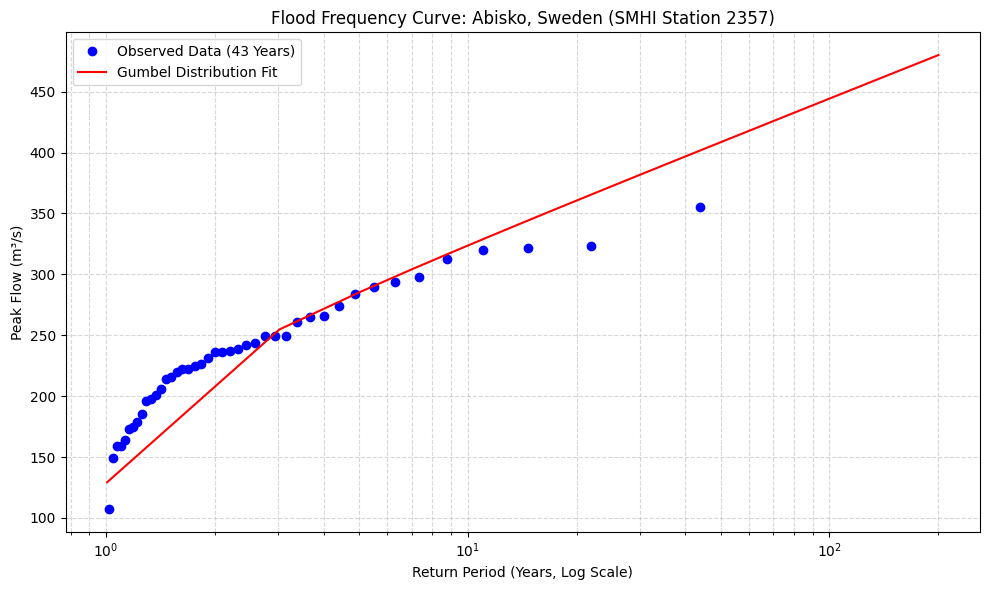

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gumbel_r

# 1. Extract the peak flows into a numpy array
peak_flows = annual_max['Flow_m3s'].values
n = len(peak_flows)

# 2. Fit the Gumbel distribution
loc, scale = gumbel_r.fit(peak_flows)

# 3. Predict the flow for 10, 50, and 100-year floods
print("--- Extreme Value Analysis Results (Abisko, Sweden) ---")
for T in [10, 50, 100]:
    prob = 1 - (1/T)
    predicted_flow = gumbel_r.ppf(prob, loc, scale)
    print(f"The {T}-year flood is predicted to be: {predicted_flow:.1f} m³/s")
print("------------------------------------------------------\n")

# 4. Calculate empirical return periods (Weibull plotting position)
ranked_flows = np.sort(peak_flows)[::-1]
ranks = np.arange(1, n + 1)
return_periods = (n + 1) / ranks

# 5. Create the Flood Frequency Curve Plot
plt.figure(figsize=(10, 6))

# Plot the empirical data (blue dots)
plt.plot(return_periods, ranked_flows, 'bo', label='Observed Data (43 Years)')

# Plot the Gumbel distribution fit (red line)
T_range = np.linspace(1.01, 200, 100)
flow_fit = gumbel_r.ppf(1 - (1/T_range), loc, scale)
plt.plot(T_range, flow_fit, 'r-', label='Gumbel Distribution Fit')

# Formatting
plt.xscale('log')
plt.title('Flood Frequency Curve: Abisko, Sweden (SMHI Station 2357)')
plt.xlabel('Return Period (Years, Log Scale)')
plt.ylabel('Peak Flow (m³/s)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()